# Homework 2 — Problem 2: Contrastive Decoding
**NYU · CSCI-GA 3033-091 · INTRO TO LLM BASED GENERATIVE AI SYSTEMS**
**Due: October 15, 2026 · 25 points**
Instructors: Parijat Dube (pd2216@nyu.edu), Chen Wang (cw4824@nyu.edu)
TAs: Raj Appana (sa9026@nyu.edu), Satyapragnya Kar (sk13001@nyu.edu)

Implement **expert–amateur contrastive decoding** from [Li et al. (2022)](https://arxiv.org/abs/2210.15097),
not Hugging Face's hidden-state-based *contrastive search*. This independently authored
implementation uses **stock Transformers 4.57** and a compatible preinstalled PyTorch
(GPU stack preserved; originally tested with 2.10), not the upstream fork. All graded functions
live in this notebook. The visible ungraded helper-export cell below supplies reusable
model/data loading, metrics, persistence, and presentation infrastructure. Upload **only this
notebook** to Colab using **File → Upload notebook**; no companion files or clone are required.

| Part / rubric item | Points |
|---|---:|
| 1. Intuition and comparison | 2 |
| 1. Objective, false positives and false negatives | 2 |
| 1. Adaptive plausibility and alpha | 2 |
| 2. Reference clone, environment, WikiText preprocessing | 2 |
| 2. Smaller same-family amateur and ablation implementation | 3 |
| 3. Nine configurations; diversity, MAUVE, coherence-proxy table | 8 |
| 3. Metric trade-offs and relation to paper | 3 |
| 3. Two–three matched best/worst examples and commentary | 3 |
| **Total: concepts 6 + setup/implementation 5 + evaluation 14** | **25** |

**Safe defaults:** model/data downloads and experiments are opt-in; package installation runs
only when you execute its setup cell. There are no stored benchmark claims or paid API calls.
Select **Runtime → Change runtime type → GPU** if available, then run setup in order.
The notebook does not need to exist in the runtime filesystem and never changes your cwd.

**Student starter: complete genuine TODO stubs below; no hidden reference implementation.**


## Part 1 — Conceptual understanding (6 points)
1. **(2 points)** Explain the intuition. Contrast this method with greedy, beam, and nucleus decoding.
   Which weaknesses of ordinary language-model generation is it trying to reduce?
2. **(2 points)** Give the contrastive objective. Explain both false-positive and false-negative behavior
   under unconstrained maximization; use examples of probability relationships, not fabricated text results.
3. **(2 points)** Explain the adaptive plausibility constraint and how alpha changes the admissible set.


### Your conceptual answers

**1. Intuition, and comparison with greedy, beam and nucleus decoding.**

- *Core intuition.* A small "amateur" LM shares the failure modes of a large "expert" LM, and exhibits them even more strongly: repetition, generic high-frequency phrasing, and loss of the topic. Where the expert is confident *and* the amateur agrees, the token is either trivially predictable or is one of those shared failure modes. Where the expert is much more confident than the amateur, the token reflects knowledge or context only the stronger model has.
- *How CD uses it.* Contrastive decoding (CD) therefore scores tokens by how much *more* the expert likes them than the amateur does, i.e. by the log-likelihood **ratio** rather than the expert's likelihood alone. It needs no training: both models are used as they are.
- *Greedy and beam search* maximise the expert's own likelihood. For open-ended text this falls into the *likelihood trap*: the highest-probability continuations are short, generic and repetitive (loops), because a repeated phrase becomes more probable each time it occurs.
- *Nucleus (top-p) sampling* avoids loops by sampling from the top-p mass. That randomness lets low-quality tokens through, which causes topic drift, incoherence and contradictions with the prompt; quality also varies from run to run.
- *What CD does differently.* It stays a deterministic **search**: the paper uses beam search, and this notebook uses greedy token-wise CD. Its objective, however, rewards tokens the expert prefers *specifically over* a weaker model. This penalises the blandness and repetition that both models share, while keeping the fluency and coherence of search.
- *Weaknesses it targets:* repetition and degeneration, generic or dull text, and incoherence or topic drift.

**2. The contrastive objective, false positives and false negatives.**

- *Objective.* For a continuation $x_{cont}$ of a prompt $x_{pre}$:
$$\mathcal{L}_{CD}(x_{cont}, x_{pre}) = \log p_{EXP}(x_{cont}\mid x_{pre}) - \log p_{AMA}(x_{cont}\mid x_{pre}).$$
  Token-wise:
$$\mathrm{score}(x_i) = \log p_{EXP}(x_i\mid x_{<i}) - \log p_{AMA}(x_i\mid x_{<i}) \text{ if } x_i \in \mathcal{V}_{head}, \text{ otherwise } -\infty.$$
  In this notebook the amateur is softened or sharpened by a temperature: $p_{AMA}(\cdot) = \mathrm{softmax}(z_{AMA}/T)$.
- *Unconstrained maximisation of the ratio fails in two directions.*
  - **False positive** (an implausible token wins):
    - token A: $p_{EXP}=10^{-6}$, $p_{AMA}=10^{-9}$, so score $=\log 10^{3}\approx 6.9$;
    - token B (a good token): $p_{EXP}=0.6$, $p_{AMA}=0.3$, so score $=\log 2\approx 0.69$.

    The ratio of two tiny probabilities can be huge, so the argmax picks A, a token the expert itself considers nearly impossible. The objective rewards "the amateur dislikes it even more", not "the expert likes it".
  - **False negative** (the correct, obvious token is penalised):
    - when the next token is essentially determined (a fixed phrase, or a name being completed), both models agree, e.g. $p_{EXP}=0.99$ and $p_{AMA}=0.95$, so score $=\log(0.99/0.95)\approx 0.04$;
    - a rare alternative with $p_{EXP}=0.005$ and $p_{AMA}=0.0001$ scores $\log 50\approx 3.9$.

    The correct token loses simply because the amateur also knows it, which breaks grammar and factual continuations.
- *How the paper avoids this.* Both failures come from scoring tokens the expert does not find plausible. The paper therefore maximises the ratio only inside a plausible set (question 3).

**3. The adaptive plausibility constraint and the role of α.**

- *Definition.*
$$\mathcal{V}_{head}(x_{<i}) = \{x\in\mathcal V : p_{EXP}(x\mid x_{<i}) \ge \alpha \max_{w} p_{EXP}(w\mid x_{<i})\}.$$
  In log space this is $\log p_{EXP}(x) \ge \log\alpha + \max_w \log p_{EXP}(w)$. Only the **expert** decides plausibility; tokens outside the set get score $-\infty$. The set always contains the expert's top token, so it is never empty.
- *Why "adaptive".* The threshold scales with the expert's confidence at that step.
  - When the expert is confident (a peaked distribution, $\max p=0.99$, $\alpha=0.1$, so the threshold is $\approx 0.099$), usually only one token survives. CD then reduces to the expert's choice, which fixes the false negatives.
  - When the expert is uncertain (a flat distribution), many tokens pass, and the amateur contrast decides among them. Tokens the expert finds implausible, like $10^{-6}$ above, are always excluded, which fixes the false positives.
- *Effect of α ∈ (0, 1].*
  - $\alpha = 1$ keeps only the expert's argmax (plus exact ties), which is plain greedy decoding of the expert.
  - $\alpha \to 0$ admits almost everything, which is unconstrained CD with its false positives.
  - Increasing α *shrinks* the admissible set: safer and more expert-like, but less influenced by the contrast and possibly less diverse. Decreasing α *enlarges* it: more room for the contrast to change the choice, at the risk of lower-probability tokens.
  - The paper and this notebook use **α = 0.1**: a token must be at least 10% as likely as the expert's best token.

## Part 2 — Setup and implementation (5 points)
### 2a. Reference checkout, environment, and preprocessing (2 points)
The handout asks for cloning the reference repository. Do this **for reading only**, outside the
submission directory, and record the actual commit returned by the commands below in `UPSTREAM_COMMIT`.
No revision has been invented or claimed as already cloned by this notebook.

```bash
git clone https://github.com/XiangLi1999/ContrastiveDecoding.git contrastive-decoding-reference
git -C contrastive-decoding-reference rev-parse HEAD
# Inspect README and equations; do NOT pip-install its transformers fork or setup.py.
```

**Colab setup (ungraded infrastructure):** run the workspace, core install, helper export,
and imports cells in that order. The workspace is temporary, absolute, and isolated by notebook
variant; rerunning setup in the same kernel reuses it. No `.py` or requirements upload is needed.
The core install preserves existing Torch/torchvision/torchaudio wheels and binary packages.
If pip reports a constraint conflict, do not force an upgrade: use a fresh compatible runtime.
If a loaded package changes, **stop and restart the runtime/session**, then rerun setup from
the top. Changing runtime type resets the environment. Local users may use their own virtual
environment; repository companion files are maintenance sources, not execution requirements.

The separate **opt-in MAUVE install** is unnecessary for pilots but required for full evaluation;
missing MAUVE, FAISS, or scikit-learn means an explicit **incomplete run**, never a proxy score.
`UPSTREAM_COMMIT = None` is allowed and honestly recorded: the handout's reading/clone task
above is separate from executing this independent implementation. If supplied, the SHA must be
40 hexadecimal characters; complete the reading task for your submission, not to unlock a pilot.
Report versions/hardware from `environment_metadata()`. Defaults are float32 GPT-2 medium
(expert) and GPT-2 small (amateur); use CUDA if available and record the device. Model sizes are
configurable, but require a smaller same-family amateur, identical token-ID mapping **and BPE
pipeline/special IDs**, and at least 1024 positions for the prescribed ablation.

**Memory/time warning:** full 500-window × nine-condition uncached generation, scoring and
MAUVE feature extraction may exceed Colab VRAM/RAM or session limits. GPU availability is not
guaranteed. `MAUVE_DEVICE_ID = -1` defaults to CPU to avoid adding another GPU model; set it to
an available GPU index only if sufficient memory remains. CPU MAUVE still consumes RAM/time.
Keep pilots labeled incomplete, and download results before the ephemeral runtime is deleted.

**Data protocol:** Hugging Face `Salesforce/wikitext`, `wikitext-103-raw-v1`, `test` split,
corresponding to the handout's [WikiText-103 source](https://academictorrents.com/details/a4fee5547056c845e31ab952598f43b42333183c).
Top-level `= Title =` lines begin articles; retain inner headings but exclude the article title.
Join article body rows with newlines; tokenize each article without added special tokens. Take
complete **768-token prompt + 128-token human continuation** candidates, stride **128**,
never crossing an article boundary. Prompts overlap within an article; reference spans do not.
Overlapping prompts are statistically dependent: discuss this and use article-level resampling
if estimating uncertainty. Stride 896 would leave too few test-split candidates for large MAUVE
runs. Seeded reservoir sampling selects the requested count uniformly from candidates; sort the
selected windows into source order. Preserve article indices/titles/token offsets, raw texts and
exact IDs. All nine conditions reuse exactly these windows.

The default full sample count is **500**; hundreds to 1,000+ windows are recommended, subject to
available complete article windows. MAUVE from a few dozen samples is unstable. A separate
**64-token-prompt, 32-token-generation, 3-window pilot** (stride 32) checks plumbing only: its prompt
does not exceed 512, so it cannot demonstrate the full-vs-half-window effect and is NOT the benchmark.
Hub revisions are resolved to immutable SHAs before model/data downloads and saved with dataset
fingerprint, seeds, versions and parameters. Reuse these SHAs for later reruns rather than `main`.


### My setup, preprocessing and implementation notes (2a, 2b)

**Reference repository (reading only).** Cloned `XiangLi1999/ContrastiveDecoding` at commit `170e9142e92159c1237d731e240f5eb14aabf428` (contents: `README.md`, `text-generation/`, `transformers/` fork). I read it for the objective and the amateur settings. I did **not** install its transformers fork, and no code was copied.

**Environment.** Google Colab, NVIDIA A100-SXM4-80GB; Python 3.13.16; PyTorch 2.11.0+cu130; transformers 4.57.6; datasets 4.8.5; numpy 2.1.3; mauve-text 0.4.0; faiss-cpu 1.15.1; scikit-learn 1.6.1. Setup steps: core install under a constraint file that protects the preinstalled Torch/GPU stack; MAUVE installed with `--no-deps`; a sanity-import check. *Incident:* an earlier MAUVE install replaced numpy's files on disk and left an unusable numpy (`numpy.rec` / "dtype size changed" errors). The fix was a fresh runtime, installing MAUVE with `--no-deps`, then `pip install --force-reinstall --no-deps numpy==2.1.3`, and a subprocess import check before any model work.

**Models.** Expert `openai-community/gpt2-medium` (354.8M parameters, revision `6dcaa7a952f72f9298047fd5137cd6e4f05f41da`); amateur `openai-community/gpt2` (124.4M parameters, revision `607a30d783dfa663caf39e06633721c8d4cfcd7e`). Same GPT-2 family, so the amateur is strictly smaller. Both tokenizers were verified to have identical token-ID maps, special IDs and BPE pipeline, and both support 1024 positions. Weights are float32.

**Data and preprocessing.** `Salesforce/wikitext`, config `wikitext-103-raw-v1`, test split, revision `b08601e04326c79dfdd32d625aee71d232d685c3` (fingerprint `c30409b5a24d230f`).
- A top-level `= Title =` row starts an article; inner headings are kept; the title is excluded; body rows are joined with newlines and each article is tokenized once with no special tokens.
- Candidate windows are 768 prompt tokens + 128 human-continuation tokens, stride 128, never crossing an article boundary. Prompts overlap within an article, reference spans do not.
- 500 windows were drawn by seeded uniform reservoir sampling (seed 17) and sorted into source order: 58 distinct articles, at most 32 windows from one article. All nine conditions reuse exactly these windows.

**Contrastive decoding implementation.**
- `contrastive_scores`: `log_softmax(expert) − log_softmax(amateur / T)`, with tokens failing the expert's log-space plausibility test (`log p_EXP ≥ log α + max log p_EXP`, α = 0.1) set to −∞. It rejects non-finite logits, T ≤ 0 or non-finite, and α outside (0, 1].
- **Amateur temperature** is applied only to the amateur's logits, before its `log_softmax` (`amateur_logits / temperature`), for T ∈ {0.5, 1.0, 1.5}.
- **Amateur context window** is changed in `contrastive_generate` / `contrastive_generate_batch`: at every step the amateur receives only `sequence[-amateur_window:]` of the running prompt-plus-generated tokens, for windows 1024 (everything), 512 (half) and 1 (latest token only). The expert always sees the full sequence (768 + 128 ≤ 1024).
- Both models are re-run each step with `use_cache=False` and `position_ids` reset to `0..length-1`, so no truncated history leaks through a KV cache. Next token = `argmax` of the scores (greedy). Generation stops immediately on EOS (not returned) or after 128 new tokens.
- *Speed-only deviation:* `contrastive_generate_batch` generates 32 equal-length prompts together (no padding needed). Per-window results were checked equal to the single-prompt function on a tiny GPT-2 offline. The transformer forward runs under fp16 autocast on the GPU (scores in float32), so a few near-tied greedy choices could differ from a pure float32 run.
- The scoring perplexity (conditional NLL under the expert) is float32.

**Metrics.** Diversity = mean of corpus micro distinct-2/3/4 (whitespace tokens). MAUVE: human continuations as `p_text`, generations as `q_text`, feature model `openai-community/gpt2` (revision `607a30d7…`), `max_text_length` 128, 25 buckets, 5 k-means redos, 500 iterations, scaling factor 5, seed 17, batch size 8, computed on CPU. Coherence proxy = token-weighted conditional perplexity of generated tokens under the expert. EOS: omitted from texts, diversity, MAUVE and NLL; token counts, empty outputs and EOS counts are recorded.

**Reproducibility.** Seeds: `torch.manual_seed(17)`, window sampling 17, MAUVE 17. Decoding is deterministic given the weights, windows, α and precision. The nine conditions took 615–800 s each (6,401 s ≈ 1 h 47 min in total). Raw outputs, token IDs and provenance are in `problem2_full.json` (submitted zip).

In [1]:
# 2a. Reference checkout for READING ONLY (not installed, not imported, outside the submission).
!git clone https://github.com/XiangLi1999/ContrastiveDecoding.git /content/contrastive-decoding-reference
!git -C /content/contrastive-decoding-reference rev-parse HEAD
!ls /content/contrastive-decoding-reference

Cloning into '/content/contrastive-decoding-reference'...
remote: Enumerating objects: 1648, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (15/15), done.
remote: Total 1648 (delta 2), reused 12 (delta 1), pack-reused 1630 (from 1)
Receiving objects: 100% (1648/1648), 259.49 MiB | 20.22 MiB/s, done.
Resolving deltas: 100% (489/489), done.
Updating files: 100% (1349/1349), done.
170e9142e92159c1237d731e240f5eb14aabf428
README.md  text-generation  transformers


In [2]:
!python -c "import numpy, scipy, sklearn; print('numpy', numpy.__version__, '| scipy', scipy.__version__, '| sklearn', sklearn.__version__)"
!pip list 2>/dev/null | grep -iE "^(numpy|scipy|scikit-learn|pandas|transformers|datasets|faiss-cpu|mauve-text) "

numpy 2.1.3 | scipy 1.16.3 | sklearn 1.6.1
datasets                              4.8.5
numpy                                 2.1.3
pandas                                2.2.3
scikit-learn                          1.6.1
scipy                                 1.16.3
transformers                          5.20.2


In [3]:
# Standard-library only; no uploads, repository discovery, or cwd changes.
from pathlib import Path
import sys
import tempfile

_P2_VARIANT = "student"
if not hasattr(sys, "_hw2_p2_workspaces"):
    sys._hw2_p2_workspaces = {}
if _P2_VARIANT not in sys._hw2_p2_workspaces:
    sys._hw2_p2_workspaces[_P2_VARIANT] = tempfile.mkdtemp(prefix=f"hw2-p2-{_P2_VARIANT}-")
P2_WORKSPACE = Path(sys._hw2_p2_workspaces[_P2_VARIANT]).resolve()
P2_WORKSPACE.mkdir(parents=True, exist_ok=True)
P2_HELPER_PATH = P2_WORKSPACE / "contrastive_utils.py"
P2_RESULTS_DIR = P2_WORKSPACE / "results"
print("P2 workspace:", P2_WORKSPACE)


P2 workspace: /tmp/hw2-p2-student-ib38sjzk


In [4]:
# Persist results on Google Drive so a Colab disconnect does not lose finished conditions.
from google.colab import drive
drive.mount("/content/drive")
P2_RESULTS_DIR = Path("/content/drive/MyDrive/hw2_p2_results")
P2_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("Results will be saved to:", P2_RESULTS_DIR)

Mounted at /content/drive
Results will be saved to: /content/drive/MyDrive/hw2_p2_results


In [5]:
# Run before importing ML libraries. No external requirements file is needed.
import importlib.metadata as _metadata
import re
import subprocess
import sys

def _p2_versions():
    return {re.sub(r"[-_.]+", "-", d.metadata["Name"]).lower(): d.version
            for d in _metadata.distributions() if d.metadata["Name"]}

def _p2_install(requirements):
    if getattr(sys, "_hw2_p2_restart_required", False):
        raise RuntimeError("Restart the runtime/session, then rerun setup from the top.")
    before = _p2_versions()
    version = before.get("torch", "")
    match = re.match(r"(\d+)\.(\d+)", version)
    if not match or tuple(map(int, match.groups())) < (2, 4):
        raise RuntimeError("Use a fresh Colab runtime with PyTorch >=2.4 (GPU recommended). "
                           "This cell deliberately does not replace your Torch/CUDA stack.")
    loaded = {name.split(".")[0] for name in sys.modules}
    loaded_distributions = {
        re.sub(r"[-_.]+", "-", dist).lower()
        for module, distributions in _metadata.packages_distributions().items()
        if module in loaded for dist in distributions
    }
    # Keep preinstalled GPU wheels and binary ABI dependencies intact, even before imports.
    protected = loaded_distributions | {
        "torch", "torchvision", "torchaudio", "numpy", "scipy", "pandas", "pyarrow",
        "scikit-learn", "matplotlib", "pillow", "faiss-cpu",
    }
    constraints = P2_WORKSPACE / "installed-stack-constraints.txt"
    constraints.write_text("".join(f"{name}=={before[name]}\n" for name in sorted(protected)
                                   if name in before), encoding="utf-8")
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "--constraint", str(constraints),
                        *requirements], check=True)
    finally:
        after = _p2_versions()
        changed = sorted(name for name in loaded_distributions
                         if before.get(name) != after.get(name))
        if changed:
            sys._hw2_p2_restart_required = True
            raise RuntimeError(f"Loaded packages changed: {changed}. STOP: restart the runtime/session "
                               "and rerun all setup cells before importing or running models.")
    print("Dependencies ready; protected the existing Torch/GPU and binary stack.")

# Resolver conflicts are intentional safety stops, not permission to force upgrades.
# Use a fresh runtime if its preinstalled stack cannot satisfy these requirements.
_p2_install(["transformers>=4.57,<4.58", "datasets>=3,<5", "pandas>=2,<3", "matplotlib>=3.8,<4"])


Dependencies ready; protected the existing Torch/GPU and binary stack.


In [6]:
# Opt in BEFORE the imports cell when planning a genuine full evaluation.
# --no-deps: Colab already ships numpy, scikit-learn, tqdm and requests; letting pip resolve
# dependencies here previously replaced numpy in place and broke its binary compatibility.
INSTALL_MAUVE = True
if INSTALL_MAUVE:
    _p2_install(["--no-deps", "mauve-text>=0.4,<0.5", "faiss-cpu>=1.8,<2"])
else:
    print("MAUVE installation skipped; pilots remain explicitly incomplete.")

Dependencies ready; protected the existing Torch/GPU and binary stack.


In [7]:
 # Diagnose what the installs changed, then restore the runtime's original numpy cleanly.
!pip list 2>/dev/null | grep -iE "^(numpy|scipy|scikit-learn|pandas|transformers|datasets|faiss-cpu|mauve-text|tokenizers|huggingface-hub) "
!pip install --force-reinstall --no-deps numpy==2.1.3
!python -c "import numpy, scipy, sklearn, faiss, mauve; from sklearn.cluster import KMeans; print('subprocess check OK, numpy', numpy.__version__)"

datasets                              4.8.5
faiss-cpu                             1.15.1
mauve-text                            0.4.0
numpy                                 1.26.4
pandas                                2.2.3
scikit-learn                          1.6.1
scipy                                 1.16.3
tokenizers                            0.22.2
transformers                          4.57.6
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 147.0 MB/s  0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4


subprocess check OK, numpy 2.1.3


In [8]:
# Sanity check: the scientific stack must import cleanly before any model work
import numpy, scipy, sklearn, faiss, mauve
print("numpy", numpy.__version__, "| scipy", scipy.__version__, "| sklearn", sklearn.__version__,
      "| faiss", faiss.__version__)
from sklearn.cluster import KMeans  # the exact import require_mauve() needs
print("MAUVE stack OK")

numpy 2.1.3 | scipy 1.16.3 | sklearn 1.6.1 | faiss 1.15.1
MAUVE stack OK


In [9]:
%%writefile "{P2_HELPER_PATH}"
"""Ungraded HW2 infrastructure; no decoding, diversity, or experiment solutions.

This file is independently distributable with the student notebook. Network/model
loading is explicit: importing the module never downloads or starts a benchmark.
"""
from __future__ import annotations

import importlib.metadata
import json
import math
import operator
from pathlib import Path
import platform
import random
import re
import sys

import torch
import torch.nn.functional as F


def context_limit(model):
    """GPT-2-style learned absolute-position capacity."""
    for name in ("max_position_embeddings", "n_positions"):
        value = getattr(model.config, name, None)
        if value is not None:
            return int(value)
    raise ValueError("Model must expose its absolute-position context capacity")


def model_device(model):
    return next(model.parameters()).device


def token_ids(ids, vocab_size):
    """Validate without silently truncating floating-point token IDs."""
    result = []
    for value in ids:
        if isinstance(value, bool):
            raise ValueError("Boolean token IDs are invalid")
        try:
            value = operator.index(value)
        except TypeError as exc:
            raise ValueError("Token IDs must be integers") from exc
        if not 0 <= value < vocab_size:
            raise ValueError("Token ID outside model vocabulary")
        result.append(value)
    return result


def validate_tokenizers(expert_tokenizer, amateur_tokenizer):
    """Require identical token-ID mapping, special IDs, and tokenization pipeline.

    Both loaders request fast tokenizers. Comparing the backend model includes
    BPE merges, not just the vocabulary; equal vocabularies alone are insufficient.
    Padding/truncation runtime settings are deliberately not part of this check.
    """
    if expert_tokenizer.get_vocab() != amateur_tokenizer.get_vocab():
        raise ValueError("Expert/amateur token-to-ID mappings differ")
    for key in ("bos_token_id", "eos_token_id", "unk_token_id", "pad_token_id"):
        if getattr(expert_tokenizer, key) != getattr(amateur_tokenizer, key):
            raise ValueError(f"Tokenizer special ID mismatch: {key}")
    if not all(getattr(t, "is_fast", False) for t in (expert_tokenizer, amateur_tokenizer)):
        raise ValueError("Fast tokenizers required to verify the BPE pipeline")
    left = json.loads(expert_tokenizer.backend_tokenizer.to_str())
    right = json.loads(amateur_tokenizer.backend_tokenizer.to_str())
    for key in ("model", "normalizer", "pre_tokenizer", "post_processor", "decoder", "added_tokens"):
        if left.get(key) != right.get(key):
            raise ValueError(f"Tokenizer pipeline mismatch: {key}")
    return True


def environment_metadata():
    packages = {}
    for package in ("torch", "transformers", "datasets", "numpy", "mauve-text", "faiss-cpu", "scikit-learn"):
        try:
            packages[package] = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            packages[package] = None
    return {
        "python": sys.version, "platform": platform.platform(), "packages": packages,
        "cuda_available": torch.cuda.is_available(),
        "cuda_devices": [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())],
        "cpu": platform.processor(),
    }


def load_model_pair(expert_id="openai-community/gpt2-medium", amateur_id="openai-community/gpt2",
                    expert_revision="main", amateur_revision="main", device="cpu"):
    """Explicit online opt-in; resolve mutable revisions to immutable Hub commits."""
    from huggingface_hub import HfApi
    from transformers import AutoModelForCausalLM, AutoTokenizer

    api = HfApi()
    expert_sha = api.model_info(expert_id, revision=expert_revision).sha
    amateur_sha = api.model_info(amateur_id, revision=amateur_revision).sha
    et = AutoTokenizer.from_pretrained(expert_id, revision=expert_sha, use_fast=True)
    at = AutoTokenizer.from_pretrained(amateur_id, revision=amateur_sha, use_fast=True)
    validate_tokenizers(et, at)
    expert = AutoModelForCausalLM.from_pretrained(expert_id, revision=expert_sha).to(device).eval()
    amateur = AutoModelForCausalLM.from_pretrained(amateur_id, revision=amateur_sha).to(device).eval()
    if any(m.config.model_type != "gpt2" for m in (expert, amateur)):
        raise ValueError("This position-handling protocol requires two GPT-2-family models")
    if any(m.get_output_embeddings().weight.shape[0] != len(et) for m in (expert, amateur)):
        raise ValueError("Model output vocabulary must exactly match tokenizer")
    expert_parameters = sum(p.numel() for p in expert.parameters())
    amateur_parameters = sum(p.numel() for p in amateur.parameters())
    if amateur_parameters >= expert_parameters:
        raise ValueError("Choose a strictly smaller amateur model than the expert")
    if min(context_limit(expert), context_limit(amateur)) < 1024:
        raise ValueError("Both models must support the prescribed 1024-position grid")
    metadata = {
        "expert": {"id": expert_id, "revision": expert_sha, "parameters": expert_parameters,
                   "context_limit": context_limit(expert)},
        "amateur": {"id": amateur_id, "revision": amateur_sha, "parameters": amateur_parameters,
                    "context_limit": context_limit(amateur)},
        "tokenizer_verified": True, "device": str(device), "dtype": str(next(expert.parameters()).dtype),
    }
    return expert, amateur, et, metadata


def article_windows(rows, tokenizer, *, count, prompt_tokens=768, reference_tokens=128, seed=17, stride=None):
    """Sample windows within WikiText top-level articles.

    A top-level '= Title =' row starts an article; '= = Section = =' does not.
    Discard pre-heading material, exclude the article title, retain section headings
    and join body rows with newlines. Tokenize each article once, with no inserted
    BOS/EOS. Default stride equals reference length: prompts overlap, but reference
    spans do not. Report this within-article dependence. Never bridge articles.
    Reservoir sampling is uniform over candidates and bounds token-window memory.
    """
    stride = reference_tokens if stride is None else stride
    for value in (count, prompt_tokens, reference_tokens, stride):
        if isinstance(value, bool) or not isinstance(value, int) or value <= 0:
            raise ValueError("Window counts, lengths and stride must be positive integers")
    rng = random.Random(seed)
    width = prompt_tokens + reference_tokens
    reservoir, seen, article_index = [], 0, -1
    title, lines = None, []

    def consume(article_title, body, index):
        nonlocal seen
        if article_title is None:
            return
        ids = tokenizer.encode("\n".join(body), add_special_tokens=False)
        for offset in range(0, len(ids) - width + 1, stride):
            seen += 1
            slot = seen - 1 if seen <= count else rng.randrange(seen)
            if slot >= count:
                continue
            prompt = ids[offset:offset + prompt_tokens]
            reference = ids[offset + prompt_tokens:offset + width]
            item = {
                "window_id": f"article-{index}:token-{offset}", "article_index": index,
                "article_title": article_title, "article_token_offset": offset,
                "article_token_count": len(ids), "prompt_ids": prompt, "reference_ids": reference,
                "prompt_text": tokenizer.decode(prompt, clean_up_tokenization_spaces=False),
                "reference_text": tokenizer.decode(reference, clean_up_tokenization_spaces=False),
            }
            if seen <= count:
                reservoir.append(item)
            else:
                reservoir[slot] = item

    for row in rows:
        text = row["text"]
        stripped = text.strip()
        is_title = bool(re.fullmatch(r"=\s+[^=].*?\s+=", stripped)) and "=" not in stripped[1:-1]
        if is_title:
            consume(title, lines, article_index)
            article_index += 1
            title, lines = stripped[1:-1].strip(), []
        elif title is not None:
            lines.append(text.rstrip("\n"))
    consume(title, lines, article_index)
    if seen < count:
        raise ValueError(f"Only {seen} complete article windows available, requested {count}")
    reservoir.sort(key=lambda w: (w["article_index"], w["article_token_offset"]))
    return reservoir


def load_wikitext_windows(tokenizer, *, count=500, prompt_tokens=768, reference_tokens=128,
                          seed=17, revision="main"):
    from datasets import load_dataset
    from huggingface_hub import HfApi

    dataset_id = "Salesforce/wikitext"
    sha = HfApi().dataset_info(dataset_id, revision=revision).sha
    dataset = load_dataset(dataset_id, "wikitext-103-raw-v1", split="test", revision=sha)
    windows = article_windows(dataset, tokenizer, count=count, prompt_tokens=prompt_tokens,
                              reference_tokens=reference_tokens, seed=seed)
    metadata = {
        "id": dataset_id, "config": "wikitext-103-raw-v1", "split": "test", "revision": sha,
        "fingerprint": dataset._fingerprint, "seed": seed, "sample_count": count,
        "prompt_tokens": prompt_tokens, "reference_tokens": reference_tokens,
        "stride": reference_tokens, "sampling": "uniform reservoir, sorted in source order",
        "window_dependence": "overlapping prompts within articles; nonoverlapping reference spans",
        "article_boundary_policy": "top-level headings; no cross-article windows; title excluded",
    }
    return windows, metadata


@torch.inference_mode()
def conditional_perplexity(model, prompts, continuations, *, pad_token_id, batch_size=8):
    """Token-weighted conditional NLL of continuation tokens only.

    Right-pad prompt+continuation and mask all prompt and padding labels to -100.
    The shifted target at the first continuation position is predicted by the
    final prompt position. EOS is excluded if absent from the supplied continuation.
    Empty continuations contribute zero targets, not a spurious zero-loss sample.
    Inputs must fit the scorer context; silently truncating would change the proxy.
    """
    if len(prompts) != len(continuations) or batch_size <= 0:
        raise ValueError("Matched prompts/continuations and positive batch_size required")
    vocab = model.get_output_embeddings().weight.shape[0]
    pad_token_id = token_ids([pad_token_id], vocab)[0]
    pairs = []
    for prompt, continuation in zip(prompts, continuations):
        p, c = token_ids(prompt, vocab), token_ids(continuation, vocab)
        if not p:
            raise ValueError("Each continuation needs a nonempty conditioning prompt")
        if len(p) + len(c) > context_limit(model):
            raise ValueError("Conditional sequence exceeds scorer position capacity")
        pairs.append((p, c))
    model.eval()
    total_nll, total_tokens = 0.0, 0
    for start in range(0, len(pairs), batch_size):
        batch = [(p, c) for p, c in pairs[start:start + batch_size] if c]
        if not batch:
            continue
        width = max(len(p) + len(c) for p, c in batch)
        ids = torch.full((len(batch), width), pad_token_id, dtype=torch.long, device=model_device(model))
        attention = torch.zeros_like(ids)
        labels = torch.full_like(ids, -100)
        for i, (p, c) in enumerate(batch):
            length = len(p) + len(c)
            ids[i, :length] = torch.tensor(p + c, device=ids.device)
            attention[i, :length] = 1
            labels[i, len(p):length] = torch.tensor(c, device=ids.device)
        positions = torch.arange(width, device=ids.device).unsqueeze(0).expand_as(ids)
        logits = model(input_ids=ids, attention_mask=attention, position_ids=positions,
                       use_cache=False).logits.float()
        targets = labels[:, 1:]
        nll = F.cross_entropy(logits[:, :-1].reshape(-1, logits.shape[-1]), targets.reshape(-1),
                              ignore_index=-100, reduction="sum")
        if not torch.isfinite(nll):
            raise ValueError("Nonfinite continuation NLL")
        total_nll += nll.item()
        total_tokens += (targets != -100).sum().item()
    mean_nll = total_nll / total_tokens if total_tokens else None
    perplexity = math.exp(mean_nll) if mean_nll is not None and mean_nll < 709 else None
    return {"nll_sum": total_nll, "scored_tokens": total_tokens, "mean_nll": mean_nll,
            "perplexity": perplexity, "empty_continuations": sum(not c for _, c in pairs)}


def require_mauve():
    """Fail explicitly: full evaluation may never substitute a proxy for MAUVE."""
    try:
        import mauve
        import faiss  # noqa: F401
        from sklearn.cluster import KMeans  # noqa: F401
    except ImportError as exc:
        raise RuntimeError("INCOMPLETE: genuine MAUVE dependencies missing. Run the notebook's optional "
                           "MAUVE install cell; pilot results are not full evaluation.") from exc
    return mauve


def prepare_mauve(*, feature_model="openai-community/gpt2", revision="main", seed=17, device_id=-1):
    """Explicit download, pinned feature-model snapshot; fixed clustering settings."""
    require_mauve()
    from huggingface_hub import HfApi, snapshot_download

    sha = HfApi().model_info(feature_model, revision=revision).sha
    local_path = snapshot_download(feature_model, revision=sha,
                                   allow_patterns=["*.json", "*.txt", "*.safetensors"])
    return {"feature_model": feature_model, "feature_revision": sha,
            "featurize_model_name": local_path, "device_id": device_id,
            "max_text_length": 128, "num_buckets": 25, "seed": seed,
            "kmeans_num_redo": 5, "kmeans_max_iter": 500, "mauve_scaling_factor": 5,
            "batch_size": 8}


def genuine_mauve(references, generations, settings):
    mauve = require_mauve()
    if len(references) != len(generations) or len(references) < settings["num_buckets"]:
        raise ValueError("MAUVE needs matched samples and at least num_buckets samples")
    if any(not text.strip() for text in references + generations):
        raise ValueError("INCOMPLETE: empty text cannot be silently removed from matched MAUVE inputs")
    keys = ("featurize_model_name", "device_id", "max_text_length", "num_buckets", "seed",
            "kmeans_num_redo", "kmeans_max_iter", "mauve_scaling_factor", "batch_size")
    result = mauve.compute_mauve(p_text=references, q_text=generations,
                                 **{key: settings[key] for key in keys}, verbose=False)
    value = float(result.mauve)
    if not math.isfinite(value) or not 0 <= value <= 1:
        raise ValueError("Invalid MAUVE result")
    return value


def save_results(path, result):
    """Persist exact token IDs, raw examples, metrics, settings and revisions."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    text = json.dumps(result, ensure_ascii=False, indent=2, allow_nan=False)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(text + "\n", encoding="utf-8")
    temporary.replace(path)


def plot_diversity(result):
    """Measured-only monochrome small multiples; the notebook also shows a table."""
    import matplotlib.pyplot as plt

    rows = result["rows"]
    if len(rows) != 9:
        raise ValueError("Plot requires all nine measured configurations")
    with plt.rc_context({"figure.facecolor": "white", "axes.facecolor": "white",
                         "text.color": "#222222", "axes.labelcolor": "#222222",
                         "xtick.color": "#222222", "ytick.color": "#222222"}):
        fig, axes = plt.subplots(1, 3, figsize=(10, 3.5), sharey=True, layout="constrained")
        for ax, window, marker in zip(axes, (1024, 512, 1), ("o", "s", "^")):
            group = sorted((r for r in rows if r["amateur_window"] == window),
                           key=lambda r: r["temperature"])
            ax.plot([r["temperature"] for r in group], [r["diversity"] for r in group],
                    color="#222222", linewidth=1.5, marker=marker, markersize=7,
                    markeredgecolor="white", markeredgewidth=1.5)
            ax.set(title=f"Amateur window: {window}", xlabel="Amateur temperature",
                   ylim=(0, 1.05), xticks=(0.5, 1.0, 1.5))
            ax.grid(axis="y", color="#e5e5e5", linewidth=0.6)
            ax.set_axisbelow(True)
            for spine in ax.spines.values():
                spine.set_color("#dddddd")
        axes[0].set_ylabel("Mean distinct-2/3/4 (higher is more diverse)")
        label = "Full evaluation" if result["complete"] else "Pilot only — MAUVE incomplete"
        fig.suptitle(f"{label}: measured continuation diversity")
    return fig


def results_table(result):
    """Plain table; no plotting dependencies or unmeasured placeholders."""
    import pandas as pd

    columns = ("temperature", "amateur_window", "distinct_2", "distinct_3", "distinct_4",
               "diversity", "mauve", "perplexity", "scored_tokens", "empty_continuations", "eos_count")
    return pd.DataFrame([{key: row[key] for key in columns} for row in result["rows"]])


Writing /tmp/hw2-p2-student-ib38sjzk/contrastive_utils.py


In [10]:
import math
import importlib.util
import sys

if getattr(sys, "_hw2_p2_restart_required", False):
    raise RuntimeError("STOP: restart the runtime/session and rerun setup from the top.")
if P2_HELPER_PATH.parent != P2_WORKSPACE or not P2_HELPER_PATH.is_file() or P2_HELPER_PATH.is_symlink():
    raise RuntimeError("Run the helper export cell into this notebook's workspace first.")
# Load the exact freshly exported source, never a cwd/sibling module or stale bytecode.
_p2_spec = importlib.util.spec_from_file_location(
    f"_hw2_p2_{_P2_VARIANT}_contrastive_utils", P2_HELPER_PATH)
_p2_helper = importlib.util.module_from_spec(_p2_spec)
exec(compile(P2_HELPER_PATH.read_bytes(), str(P2_HELPER_PATH), "exec"), _p2_helper.__dict__)
sys.modules[_p2_spec.name] = _p2_helper
sys.modules["contrastive_utils"] = _p2_helper
import torch
from contrastive_utils import (
    context_limit, model_device, token_ids, environment_metadata, load_model_pair,
    load_wikitext_windows, conditional_perplexity, require_mauve, prepare_mauve,
    genuine_mauve, save_results, results_table, plot_diversity,
)

RUN_PILOT = False
RUN_FULL_EVALUATION = True
SHOW_RESULTS = True
UPSTREAM_COMMIT = "170e9142e92159c1237d731e240f5eb14aabf428"  # Optional runtime metadata; record the actual SHA after the reading task.
EXPERT_ID = "openai-community/gpt2-medium"
AMATEUR_ID = "openai-community/gpt2"
EXPERT_REVISION = "main"  # Replace with recorded resolved SHA to reproduce a previous run.
AMATEUR_REVISION = "main"
DATA_REVISION = "main"
FEATURE_REVISION = "main"
SEED = 17
FULL_SAMPLE_COUNT = 500
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MAUVE_DEVICE_ID = -1  # CPU; opt into a visible GPU index only with sufficient free VRAM.
RESULTS = None
print(environment_metadata())


{'python': '3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]', 'platform': 'Linux-6.6.122+-x86_64-with-glibc2.39', 'packages': {'torch': '2.11.0+cu130', 'transformers': '4.57.6', 'datasets': '4.8.5', 'numpy': '2.1.3', 'mauve-text': '0.4.0', 'faiss-cpu': '1.15.1', 'scikit-learn': '1.6.1'}, 'cuda_available': True, 'cuda_devices': ['NVIDIA A100-SXM4-80GB'], 'cpu': 'x86_64'}


### 2b. Expert–amateur implementation and ablations (3 points)
Implement the four core tasks below (experiment/evaluation and selection follow in Part 3).

* `contrastive_scores`: compute `log_softmax(expert_logits) - log_softmax(amateur_logits / T)`;
  set entries failing the **expert** log-space plausibility test to negative infinity. Reject
  nonfinite logits, nonpositive/nonfinite temperature, and alpha outside `(0, 1]`.
* `contrastive_generate`: select the admissible maximum at each step; PyTorch `argmax` uses the
  lowest token ID on a tie. Recompute expert and amateur forwards with **`use_cache=False`**.
  The amateur sees only the latest `amateur_window` tokens; reset learned absolute positions
  to `0..window_length-1` after truncation. This prevents hidden KV-cache leakage from dropped
  history. The expert also uses its own capacity as a rolling maximum; for the benchmark the
  768+128 tokens fit without expert truncation. Return continuation IDs **excluding terminal EOS**,
  the stop reason and EOS flag. Stop immediately on EOS or at the token budget; never pad output.
* Temperature acts on **amateur logits before normalization**, not the expert or final score.
* Test **all nine** combinations: temperatures `0.5, 1.0, 1.5` and rolling windows `1024, 512, 1`.
  The benchmark prompt is longer than 512 so the full/half contrast is meaningful at step one.

**Scope versus paper:** we implement deterministic **greedy, tokenwise CD**, not the paper's
five-beam sequence search. The handout's **rolling one-token amateur** sees only the latest token
at *every* step. This is different from the paper's restricted *initial prompt*, after which
**all generated history is retained**. Resetting positions is an additional explicit convention.
Do not call these runs an exact replication of the paper's decoding protocol.


In [11]:
def contrastive_scores(expert_logits, amateur_logits, temperature=1.0, alpha=0.1):
    """One vocabulary vector of constrained log likelihood-ratio scores."""
    if not torch.is_tensor(expert_logits) or not torch.is_tensor(amateur_logits):
        raise TypeError("expert_logits and amateur_logits must be tensors")
    if expert_logits.shape != amateur_logits.shape or expert_logits.dim() < 1 or expert_logits.shape[-1] < 1:
        raise ValueError("expert and amateur logits must have the same nonempty (..., vocab) shape")
    if isinstance(temperature, bool) or not isinstance(temperature, (int, float)) \
            or not math.isfinite(temperature) or temperature <= 0:
        raise ValueError("temperature must be a finite positive number")
    if isinstance(alpha, bool) or not isinstance(alpha, (int, float)) \
            or not math.isfinite(alpha) or not 0 < alpha <= 1:
        raise ValueError("alpha must be in (0, 1]")
    expert_logits = expert_logits.float()
    amateur_logits = amateur_logits.float()
    if not torch.isfinite(expert_logits).all() or not torch.isfinite(amateur_logits).all():
        raise ValueError("logits must be finite")

    expert_logp = torch.log_softmax(expert_logits, dim=-1)
    amateur_logp = torch.log_softmax(amateur_logits / temperature, dim=-1)   # T acts on amateur logits only
    threshold = math.log(alpha) + expert_logp.max(dim=-1, keepdim=True).values
    plausible = expert_logp >= threshold                                      # max token always passes
    scores = expert_logp - amateur_logp
    return scores.masked_fill(~plausible, float("-inf"))



In [12]:
def _last_position_logits(model, input_ids):
    """Fresh forward (use_cache=False) with positions rebased to 0..L-1; logits of the LAST position only.

    Only the final hidden state goes through the LM head, so we never materialise a (B, L, vocab) tensor.
    input_ids: LongTensor (B, L) with equal lengths across the batch (no padding needed).
    """
    batch, length = input_ids.shape
    positions = torch.arange(length, device=input_ids.device).unsqueeze(0).expand(batch, length)
    hidden = model.transformer(input_ids=input_ids, position_ids=positions, use_cache=False).last_hidden_state
    return model.lm_head(hidden[:, -1, :]).float()                          # (B, vocab)


def _check_generation_args(expert, amateur, temperature, alpha, amateur_window, max_new_tokens):
    if isinstance(amateur_window, bool) or not isinstance(amateur_window, int) or amateur_window <= 0:
        raise ValueError("amateur_window must be a positive integer")
    if isinstance(max_new_tokens, bool) or not isinstance(max_new_tokens, int) or max_new_tokens <= 0:
        raise ValueError("max_new_tokens must be a positive integer")
    contrastive_scores(torch.zeros(2), torch.zeros(2), temperature, alpha)  # validates T and alpha
    return min(amateur_window, context_limit(amateur)), context_limit(expert)


@torch.inference_mode()
def contrastive_generate(expert, amateur, prompt_ids, *, temperature=1.0, alpha=0.1, amateur_window=1024, max_new_tokens=128, eos_token_id=None):
    """Deterministic greedy CD with fresh, rebased rolling-context forwards.

    At every step:
      * expert sees the last context_limit(expert) tokens (all 768+128 benchmark tokens fit, so no truncation);
      * amateur sees only the last `amateur_window` tokens (1024 = everything, 512 = half, 1 = latest token);
      * both run WITHOUT a KV cache and with positions reset to 0..len-1, so no dropped history leaks in;
      * next token = argmax of contrastive_scores (torch.argmax -> lowest token ID on ties).
    Returns (continuation_ids, stop_reason, hit_eos): IDs exclude a terminal EOS; stop_reason is
    "eos" or "max_new_tokens"; generation never pads.
    """
    amateur_ctx, expert_ctx = _check_generation_args(expert, amateur, temperature, alpha,
                                                     amateur_window, max_new_tokens)
    vocab = expert.get_output_embeddings().weight.shape[0]
    sequence = token_ids(prompt_ids, vocab)
    if not sequence:
        raise ValueError("prompt_ids must be nonempty")
    device = model_device(expert)
    generated = []
    for _ in range(max_new_tokens):
        e_ids = torch.tensor([sequence[-expert_ctx:]], dtype=torch.long, device=device)
        a_ids = torch.tensor([sequence[-amateur_ctx:]], dtype=torch.long, device=model_device(amateur))
        scores = contrastive_scores(_last_position_logits(expert, e_ids)[0],
                                    _last_position_logits(amateur, a_ids)[0].to(device),
                                    temperature, alpha)
        next_id = int(torch.argmax(scores).item())
        if eos_token_id is not None and next_id == eos_token_id:
            return generated, "eos", True                       # terminal EOS is not returned
        generated.append(next_id)
        sequence.append(next_id)
    return generated, "max_new_tokens", False


@torch.inference_mode()
def contrastive_generate_batch(expert, amateur, prompt_batch, *, temperature=1.0, alpha=0.1, amateur_window=1024,
                               max_new_tokens=128, eos_token_id=None, autocast_dtype=None):
    """Same algorithm as contrastive_generate, for a batch of EQUAL-LENGTH prompts (speed only).

    All benchmark prompts are exactly 768 tokens, so every row has the same length at every step:
    no padding or attention mask is needed and per-row results are identical to the single version
    (checked in the equivalence cell). A row that hits EOS is frozen: its later tokens are discarded.
    autocast_dtype=torch.float16 optionally runs the transformer in fp16 on CUDA (scores still float32).
    Returns a list of (continuation_ids, stop_reason, hit_eos) in input order.
    """
    amateur_ctx, expert_ctx = _check_generation_args(expert, amateur, temperature, alpha,
                                                     amateur_window, max_new_tokens)
    vocab = expert.get_output_embeddings().weight.shape[0]
    prompts = [token_ids(p, vocab) for p in prompt_batch]
    if not prompts or len({len(p) for p in prompts}) != 1 or not prompts[0]:
        raise ValueError("prompt_batch must contain nonempty prompts of identical length")
    device = model_device(expert)
    sequences = torch.tensor(prompts, dtype=torch.long, device=device)
    outputs = [[] for _ in prompts]
    finished = [False] * len(prompts)
    use_amp = autocast_dtype is not None and device.type == "cuda"
    for _ in range(max_new_tokens):
        with torch.autocast("cuda", dtype=autocast_dtype, enabled=use_amp):
            e_logits = _last_position_logits(expert, sequences[:, -expert_ctx:])
            a_logits = _last_position_logits(amateur, sequences[:, -amateur_ctx:])
        next_ids = torch.argmax(contrastive_scores(e_logits, a_logits, temperature, alpha), dim=-1)
        for row, token in enumerate(next_ids.tolist()):
            if finished[row]:
                continue
            if eos_token_id is not None and token == eos_token_id:
                finished[row] = True
            else:
                outputs[row].append(token)
        if all(finished):
            break
        sequences = torch.cat([sequences, next_ids.unsqueeze(1)], dim=1)
    return [(out, "eos" if done else "max_new_tokens", done) for out, done in zip(outputs, finished)]

## Part 3 — Evaluation and analysis (14 points)
### 3a. Nine-condition generation and metrics (8 points)
**Predeclare the measurements before generating anything.**

* **Diversity:** continuation-only corpus-level distinct-2, distinct-3, distinct-4. Split each
  decoded continuation on whitespace, retaining case and punctuation; never join n-grams across
  samples. Numerator = unique n-grams over the corpus; denominator = total within-sample n-gram
  occurrences over the corpus. An empty denominator gives 0. Longer samples affect this micro
  aggregation more. It is not the paper's repetition-based diversity product; we use the handout's
  allowed distinct-n option. **Ranking** is the arithmetic mean of these three distinct-n values,
  decreasing; break exact ties by increasing temperature, then decreasing window size. Best =
  first and worst = last in that total ordering. Ties are not evidence of a substantive difference.
* **MAUVE:** genuine `mauve.compute_mauve`, human continuations as `p_text`, generated continuations
  as `q_text`, no prompts. Fixed GPT-2 feature-model revision, `max_text_length=128`, 25 buckets,
  5 k-means redos, 500 k-means iterations, scaling factor 5, seed 17, batch size 8. Report these
  settings: scores change with feature extractor, sample size and clustering. Empty texts or missing
  dependencies make the full evaluation incomplete, not a reason to silently filter examples.
  No proxy or dummy MAUVE numbers are accepted. Feature tokens differ from whitespace diversity tokens.
* **Coherence proxy:** conditional continuation perplexity under the **same fixed expert scorer**
  for every condition. Sum autoregressive negative log likelihood on generated text tokens only;
  divide by the total scored continuation tokens, then exponentiate. Prompt/padding labels are `-100`.
  This is NOT mean per-sequence perplexity and is NOT direct semantic coherence or the paper's SimCSE
  metric. Using the expert/GPT-2 family biases evaluation toward its own style and probabilities.
  Document that dependence rather than interpreting low perplexity as factual correctness.
* **EOS:** terminate and omit EOS from decoded text, diversity, MAUVE and NLL. Thus generated lengths
  may be shorter than the 128-token human continuation. Record token counts, empty outputs and EOS
  counts; discuss this length confound. Empty continuations contribute no NLL targets; all-empty
  results yield `None`, not a fabricated perplexity. Full MAUVE then fails explicitly.

MAUVE is deliberately unavailable in the small pilot; its rows carry `None` and an incomplete
status. Results tables and plots are created only from actual returned measurements. A full run
is expensive: two uncached forwards per generated token for 9 × sample-count × 128 steps, plus
scoring and MAUVE features. Use a GPU and budget accordingly. Never label the pilot a full run.


In [13]:
def distinct_n(texts, n):
    """Corpus micro distinct-n; whitespace tokens, no cross-sample n-grams."""
    if isinstance(n, bool) or not isinstance(n, int) or n <= 0:
        raise ValueError("n must be a positive integer")
    if isinstance(texts, str) or not all(isinstance(t, str) for t in texts):
        raise TypeError("texts must be a sequence of strings")
    unique, total = set(), 0
    for text in texts:
        tokens = text.split()
        grams = [tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1)]
        total += len(grams)
        unique.update(grams)
    return len(unique) / total if total else 0.0



In [14]:
import time
import json   # RESUME

TEMPERATURES = (0.5, 1.0, 1.5)
AMATEUR_WINDOWS = (1024, 512, 1)
GEN_BATCH_SIZE = 32          # A100: 32 windows per batch
GEN_AUTOCAST_FP16 = True     # fp16 autocast for generation on CUDA; scoring/perplexity stay float32
RESUME_FROM_CHECKPOINT = True  # RESUME: reuse finished conditions from a matching checkpoint on Drive


def _condition_key(temperature, window):
    return f"T={temperature}|window={window}"


def run_experiment(expert, amateur, tokenizer, windows, *, alpha=0.1, max_new_tokens=128, full_run=False, mauve_settings=None, provenance=None):
    """Run exactly nine matched conditions; incomplete pilots are labeled explicitly.

    Every condition (3 amateur temperatures x 3 rolling amateur windows) decodes the SAME windows with
    greedy contrastive decoding. Per condition we record continuation-only distinct-2/3/4 and their mean,
    genuine MAUVE (full run only; human continuations = p_text, generations = q_text), conditional
    perplexity of the generated tokens under the fixed expert scorer, token counts, empty outputs and EOS.
    Results are saved after every condition; with RESUME_FROM_CHECKPOINT, finished conditions from a
    checkpoint with identical windows and settings are reused instead of regenerated.
    """
    if not windows:
        raise ValueError("windows must be nonempty")
    if full_run and mauve_settings is None:
        raise ValueError("A full run requires genuine MAUVE settings (run prepare_mauve)")
    eos_id = tokenizer.eos_token_id
    prompts = [list(w["prompt_ids"]) for w in windows]
    references = [w["reference_text"] for w in windows]
    autocast_dtype = torch.float16 if GEN_AUTOCAST_FP16 else None
    result = {
        "complete": False,
        "status": "running",
        "run_type": "full" if full_run else "pilot (plumbing check only; MAUVE not computed)",
        "settings": {"alpha": alpha, "max_new_tokens": max_new_tokens, "temperatures": list(TEMPERATURES),
                     "amateur_windows": list(AMATEUR_WINDOWS), "decoding": "greedy token-wise contrastive decoding",
                     "use_cache": False, "position_ids": "rebased to 0..len-1 every step",
                     "batch_size": GEN_BATCH_SIZE,
                     "generation_dtype": "float16 autocast" if (GEN_AUTOCAST_FP16 and model_device(expert).type == "cuda") else "float32",
                     "coherence_proxy": "conditional continuation perplexity under the expert (token-weighted)",
                     "diversity": "mean of corpus micro distinct-2/3/4 on whitespace tokens",
                     "mauve": None if mauve_settings is None else
                              {k: v for k, v in mauve_settings.items() if k != "featurize_model_name"}},
        "provenance": provenance or {},
        "windows": [{k: w[k] for k in ("window_id", "article_index", "article_title", "article_token_offset",
                                       "prompt_ids", "reference_ids", "prompt_text", "reference_text")}
                    for w in windows],
        "rows": [],
        "samples": {},
    }
    out_path = P2_RESULTS_DIR / ("problem2_full.json" if full_run else "problem2_pilot.json")

    # RESUME: reuse finished conditions only if the checkpoint has the same windows and settings
    if RESUME_FROM_CHECKPOINT and out_path.is_file():
        old = json.loads(out_path.read_text())
        same_windows = [w["window_id"] for w in old.get("windows", [])] == [w["window_id"] for w in result["windows"]]
        same_prompts = same_windows and all(a["prompt_ids"] == b["prompt_ids"]
                                            for a, b in zip(old["windows"], result["windows"]))
        keys = ("alpha", "max_new_tokens", "temperatures", "amateur_windows", "generation_dtype", "mauve")
        same_settings = all(old.get("settings", {}).get(k) == result["settings"].get(k) for k in keys)
        if same_prompts and same_settings and old.get("run_type") == result["run_type"]:
            result["rows"], result["samples"] = old["rows"], old["samples"]
            print(f"RESUME: reusing {len(result['rows'])} finished condition(s) from {out_path}")
        else:
            print("RESUME: checkpoint does not match these windows/settings; starting fresh")

    for temperature in TEMPERATURES:
        for window in AMATEUR_WINDOWS:
            key = _condition_key(temperature, window)
            if key in result["samples"]:                      # RESUME: already finished
                print(f"{key:<22} (reused from checkpoint)")
                continue
            started = time.perf_counter()
            generations = []
            for start in range(0, len(prompts), GEN_BATCH_SIZE):
                generations += contrastive_generate_batch(
                    expert, amateur, prompts[start:start + GEN_BATCH_SIZE], temperature=temperature,
                    alpha=alpha, amateur_window=window, max_new_tokens=max_new_tokens,
                    eos_token_id=eos_id, autocast_dtype=autocast_dtype)
                print(f"  {key}: {min(start + GEN_BATCH_SIZE, len(prompts))}/{len(prompts)} windows", end="\r")
            ids = [g[0] for g in generations]
            texts = [tokenizer.decode(i, clean_up_tokenization_spaces=False) for i in ids]
            ppl = conditional_perplexity(expert, prompts, ids, pad_token_id=eos_id)
            d2, d3, d4 = (distinct_n(texts, n) for n in (2, 3, 4))
            empty = sum(not t.strip() for t in texts)
            mauve_value, mauve_status = None, "not computed (pilot)"
            if full_run:
                if empty:
                    mauve_status = f"INCOMPLETE: {empty} empty continuation(s); MAUVE not computed"
                else:
                    mauve_value = genuine_mauve(references, texts, mauve_settings)
                    mauve_status = "computed"
            lengths = [len(i) for i in ids]
            result["rows"].append({
                "condition": key, "temperature": temperature, "amateur_window": window,
                "distinct_2": d2, "distinct_3": d3, "distinct_4": d4, "diversity": (d2 + d3 + d4) / 3,
                "mauve": mauve_value, "mauve_status": mauve_status,
                "perplexity": ppl["perplexity"], "mean_nll": ppl["mean_nll"], "scored_tokens": ppl["scored_tokens"],
                "empty_continuations": empty, "eos_count": sum(g[2] for g in generations),
                "generated_tokens_total": sum(lengths), "generated_tokens_mean": sum(lengths) / len(lengths),
                "generated_tokens_min": min(lengths), "generated_tokens_max": max(lengths),
                "seconds": time.perf_counter() - started,
            })
            result["samples"][key] = [{"window_id": w["window_id"], "continuation_ids": g[0], "text": t,
                                       "stop_reason": g[1], "eos": g[2]}
                                      for w, g, t in zip(windows, generations, texts)]
            save_results(out_path, result)                     # checkpoint after every condition (on Drive)
            print(f"{key:<22} diversity={result['rows'][-1]['diversity']:.4f} "
                  f"ppl={ppl['perplexity'] if ppl['perplexity'] is None else round(ppl['perplexity'], 2)} "
                  f"mauve={mauve_value} eos={result['rows'][-1]['eos_count']} "
                  f"({result['rows'][-1]['seconds']:.0f}s)")
    # keep rows in the fixed condition order, whether reused or new
    order = {_condition_key(t, w): i for i, (t, w) in enumerate((t, w) for t in TEMPERATURES for w in AMATEUR_WINDOWS)}
    result["rows"].sort(key=lambda r: order[r["condition"]])
    all_mauve = all(r["mauve"] is not None for r in result["rows"])
    result["complete"] = bool(full_run and all_mauve and len(result["rows"]) == 9)
    result["status"] = ("complete: nine conditions with genuine MAUVE" if result["complete"] else
                        "INCOMPLETE: pilot or missing MAUVE; not a full evaluation")
    save_results(out_path, result)
    return result

In [15]:
def select_examples(result, count=3):
    """Return real matched prompts and raw best/worst continuations, never templates.

    Ranking (predeclared): mean distinct-2/3/4 descending; exact ties broken by increasing temperature,
    then decreasing amateur window. Best = first, worst = last. Examples = the first `count` windows in
    source order (not cherry-picked), each showing the same prompt under the best and worst settings.
    """
    if isinstance(count, bool) or not isinstance(count, int) or count <= 0:
        raise ValueError("count must be a positive integer")
    rows = result["rows"]
    if len(rows) != 9:
        raise ValueError("Selection requires all nine measured conditions")
    ranked = sorted(rows, key=lambda r: (-r["diversity"], r["temperature"], -r["amateur_window"]))
    best, worst = ranked[0], ranked[-1]
    best_samples, worst_samples = result["samples"][best["condition"]], result["samples"][worst["condition"]]
    examples = []
    for window, b, w in list(zip(result["windows"], best_samples, worst_samples))[:count]:
        if not (window["window_id"] == b["window_id"] == w["window_id"]):
            raise ValueError("Samples are not aligned with windows")
        examples.append({"window_id": window["window_id"], "article_title": window["article_title"],
                         "prompt": window["prompt_text"], "human": window["reference_text"],
                         "best": b["text"], "worst": w["text"],
                         "best_tokens": len(b["continuation_ids"]), "worst_tokens": len(w["continuation_ids"]),
                         "best_eos": b["eos"], "worst_eos": w["eos"]})
    return {"best": best["condition"], "worst": worst["condition"],
            "best_diversity": best["diversity"], "worst_diversity": worst["diversity"],
            "ranking": [r["condition"] for r in ranked],
            "all_diversity_tied": len({r["diversity"] for r in rows}) == 1,
            "examples": examples}

In [16]:
if getattr(sys, "_hw2_p2_restart_required", False):
    raise RuntimeError("STOP: restart the runtime/session and rerun setup before experiments.")
if RUN_PILOT and RUN_FULL_EVALUATION:
    raise ValueError("Choose either the pilot or the full evaluation, not both")
if RUN_PILOT or RUN_FULL_EVALUATION:
    if UPSTREAM_COMMIT is not None and (not isinstance(UPSTREAM_COMMIT, str) or
            len(UPSTREAM_COMMIT) != 40 or any(c not in "0123456789abcdefABCDEF" for c in UPSTREAM_COMMIT)):
        raise ValueError("UPSTREAM_COMMIT must be None or an actual 40-character hexadecimal checkout SHA")
    if RUN_FULL_EVALUATION:
        require_mauve()  # Preflight BEFORE downloading expert/data.
        if (isinstance(MAUVE_DEVICE_ID, bool) or not isinstance(MAUVE_DEVICE_ID, int) or
                MAUVE_DEVICE_ID < -1 or MAUVE_DEVICE_ID >= torch.cuda.device_count()):
            raise ValueError("MAUVE_DEVICE_ID must be -1 (CPU) or an available CUDA device index")
        print("Full 500-window evaluation may exceed Colab memory or session time; save results promptly.")
    torch.manual_seed(SEED)
    expert, amateur, tokenizer, model_metadata = load_model_pair(
        EXPERT_ID, AMATEUR_ID, EXPERT_REVISION, AMATEUR_REVISION, DEVICE)
    windows, data_metadata = load_wikitext_windows(tokenizer,
        count=FULL_SAMPLE_COUNT if RUN_FULL_EVALUATION else 3,
        prompt_tokens=768 if RUN_FULL_EVALUATION else 64,
        reference_tokens=128 if RUN_FULL_EVALUATION else 32,
        seed=SEED, revision=DATA_REVISION)
    mauve_settings = (prepare_mauve(seed=SEED, revision=FEATURE_REVISION,
        device_id=MAUVE_DEVICE_ID) if RUN_FULL_EVALUATION else None)
    RESULTS = run_experiment(expert, amateur, tokenizer, windows,
        max_new_tokens=128 if RUN_FULL_EVALUATION else 32, full_run=RUN_FULL_EVALUATION,
        mauve_settings=mauve_settings,
        provenance={"models": model_metadata, "dataset": data_metadata, "seed": SEED,
                    "reference_repository": "https://github.com/XiangLi1999/ContrastiveDecoding",
                    "reference_commit": UPSTREAM_COMMIT, "implementation": "independent; no upstream code copied"})
    save_results(P2_RESULTS_DIR / ("problem2_full.json" if RUN_FULL_EVALUATION else "problem2_pilot.json"), RESULTS)


Full 500-window evaluation may exceed Colab memory or session time; save results promptly.


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/718 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

...

Featurizing q:   0%|          | 0/63 [00:00<?, ?it/s]

T=1.5|window=512       diversity=0.7295 ppl=3.22 mauve=0.8633795719806613 eos=26 (720s)


Featurizing p:   0%|          | 0/63 [00:00<?, ?it/s]

Featurizing q:   0%|          | 0/63 [00:00<?, ?it/s]

T=1.5|window=1         diversity=0.3277 ppl=1.94 mauve=0.062540263762398 eos=3 (615s)


,temperature,amateur_window,distinct_2,distinct_3,distinct_4,diversity,mauve,perplexity,scored_tokens,empty_continuations,eos_count
0,0.5,1024,0.735052,0.928878,0.964487,0.876139,0.917011,9.095754,59420,0,80
1,0.5,512,0.725676,0.927158,0.965577,0.872804,0.959469,7.737974,60655,0,48
2,0.5,1,0.257397,0.345001,0.384349,0.328916,0.056052,2.221189,63659,0,3
3,1.0,1024,0.656635,0.865241,0.915887,0.812588,0.916011,6.065535,60027,0,53
4,1.0,512,0.660257,0.871294,0.923806,0.818452,0.947013,4.960472,60096,0,56
5,1.0,1,0.260873,0.347494,0.387028,0.331798,0.079195,2.056092,63509,0,5
6,1.5,1024,0.533648,0.734135,0.803712,0.690498,0.720239,3.755369,61294,0,34
7,1.5,512,0.563674,0.777719,0.847188,0.729527,0.863380,3.220952,61958,0,26
8,1.5,1,0.256468,0.343047,0.383530,0.327682,0.062540,1.940245,63667,0,3


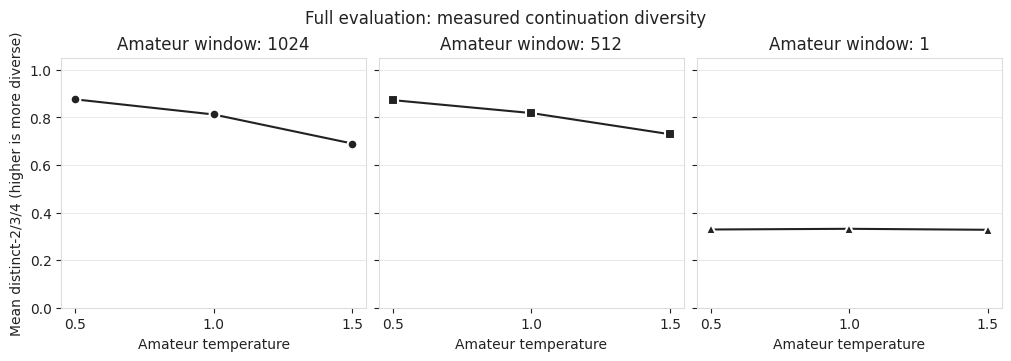

Measured best: T=0.5|window=1024 Measured worst: T=1.5|window=1

WINDOW article-0:token-256
PROMPT (raw):
 ham . Boulter starred in two films in 2008 , Daylight Robbery by filmmaker Paris Leonti , and Donkey Punch directed by Olly Blackburn . In May 2008 , Boulter made a guest appearance on a two @-@ part episode arc of the television series Waking the Dead , followed by an appearance on the television series Survivors in November 2008 . He had a recurring role in ten episodes of the television series Casualty in 2010 , as " Kieron Fletcher " . Boulter starred in the 2011 film Mercenaries directed by Paris Leonti . 

 = = Career = = 


 = = = 2000 – 2005 = = = 

 In 2000 Boulter had a guest @-@ starring role on the television series The Bill ; he portrayed " Scott Parry " in the episode , " In Safe Hands " . Boulter starred as " Scott " in the play Herons written by Simon Stephens , which was performed in 2001 at the Royal Court Theatre . A review of Boulter 's performance in The Indep

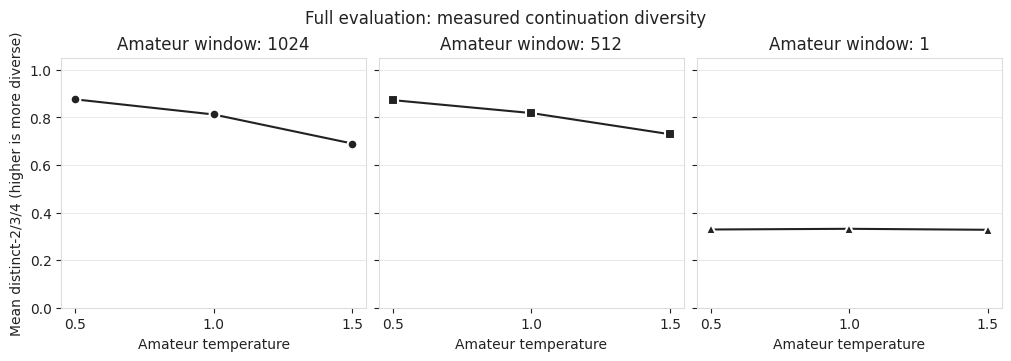

In [17]:
if SHOW_RESULTS:
    if RESULTS is None:
        raise RuntimeError("No measured results: run a pilot/full evaluation first")
    from IPython.display import display
    display(results_table(RESULTS))
    display(plot_diversity(RESULTS))
    examples = select_examples(RESULTS, count=3)
    print("Measured best:", examples["best"], "Measured worst:", examples["worst"])
    if examples["all_diversity_tied"]:
        print("All diversity scores tie; ordering is only the predeclared tie-break.")
    for example in examples["examples"]:
        print("\nWINDOW", example["window_id"])
        print("PROMPT (raw):\n", example["prompt"])
        print("HUMAN CONTINUATION (raw):\n", example["human"])
        print("BEST CONTINUATION (raw):\n", example["best"])
        print("WORST CONTINUATION (raw):\n", example["worst"])


In [18]:
# Runtime storage is ephemeral. Opt in to download only your measured results.
DOWNLOAD_RESULTS = True
if DOWNLOAD_RESULTS:
    import shutil
    if not P2_RESULTS_DIR.is_dir() or not any(P2_RESULTS_DIR.iterdir()):
        raise RuntimeError("No saved results yet; run an experiment first.")
    archive = shutil.make_archive(str(P2_WORKSPACE / "problem2-results"), "zip", P2_RESULTS_DIR)
    print("Results archive:", archive)
    try:
        from google.colab import files
    except ImportError:
        print("Local runtime: save the archive from the path above.")
    else:
        files.download(archive)


Results archive: /tmp/hw2-p2-student-ib38sjzk/problem2-results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 3b. Analysis and relation to the paper (3 points)
**Pending actual full evaluation — do not infer winners from the algorithm or offline unit tests.**
Report the measured top setting for each of diversity (higher), MAUVE (higher) and conditional
perplexity (lower), including exact ties. Contrast the 1024/512/1 context curves across temperatures.
Describe metric disagreements, length/EOS effects, uncertainty from finite samples, and scorer-family
bias. Do not interpret diversity alone as quality. How do the findings compare with the paper,
considering greedy versus five-beam search, rolling versus prompt-only context restriction,
model sizes, sampling windows, distinct-n versus repetition diversity, and perplexity versus SimCSE?

**Your measured discussion.** *(Measured full run: 500 windows, 768-token prompts, 128-token human references, GPT-2 medium expert, GPT-2 small amateur, α = 0.1, greedy CD, 9 conditions; numbers from the table above.)*

**Best setting per metric (no exact ties).**

| Metric | Best | Worst |
|---|---|---|
| Diversity (higher) | T=0.5, window 1024: **0.8761** (next: T=0.5, 512: 0.8728) | T=1.5, window 1: 0.3277 |
| MAUVE (higher) | **T=0.5, window 512: 0.9595** (next: T=1.0, 512: 0.9470) | T=0.5, window 1: 0.0561 |
| Conditional perplexity (lower) | T=1.5, window 1: **1.94** (next: T=1.0, window 1: 2.06) | T=0.5, window 1024: 9.10 |

**Context-window curves.**
- *Window 1 collapses everything:* diversity ≈ 0.33 (0.3289 / 0.3318 / 0.3277 for T = 0.5 / 1.0 / 1.5), MAUVE only 0.056–0.079, and the amateur's temperature hardly matters. In the saved text, **94% (T=0.5) and 92% (T=1.5) of the 500 continuations contain a repeated 8-gram**, versus about 5–6% for windows 1024 and 512 at T=0.5.
- *Half window (512) matches or beats the full window (1024).* MAUVE is higher at every temperature: 0.9595 vs 0.9170 (T=0.5), 0.9470 vs 0.9160 (T=1.0), 0.8634 vs 0.7202 (T=1.5); perplexity is also lower (7.74 vs 9.10, 4.96 vs 6.07, 3.22 vs 3.76). Diversity is essentially tied at T=0.5 (0.8728 vs 0.8761) and higher for 512 at T=1.0 and 1.5 (0.8185 vs 0.8126, 0.7295 vs 0.6905).
- *Temperature, for windows 1024 and 512:* raising the amateur temperature lowers diversity (window 1024: 0.876 → 0.813 → 0.690) and MAUVE (0.917 → 0.916 → 0.720; the first drop is within noise). A natural explanation is that a higher T flattens the amateur's distribution, so subtracting its log-probability penalises less, and CD moves toward plain greedy expert decoding. This is an interpretation, not something this experiment isolates.

**Metric disagreement: perplexity is not quality.** The lowest perplexities (1.94–2.22) belong to the three window-1 conditions, which are the *worst* on diversity and MAUVE. Repetitive loops are highly predictable under the expert, so low conditional perplexity here signals repetition, not coherence. Within the windows 1024/512, lower perplexity coincides with higher MAUVE (512), but across window 1 the relationship reverses. Diversity alone is also not quality: it rewards fresh n-grams even when the text drifts off topic (see 3c).

**Length and EOS confound.** The human continuation is always 128 tokens. Generated continuations are shorter when the model emits EOS: **80 / 48 / 3 of 500 at T=0.5** (windows 1024 / 512 / 1), 53 / 56 / 5 at T=1.0, 34 / 26 / 3 at T=1.5. The mean generated length is 118.8–123.9 tokens for windows 1024 and 512 (a minimum of just 2 tokens) and 127.0–127.3 for window 1, and the total scored tokens differ by up to 6.7% (59,420 vs 63,659). Window 1 almost never stops, so its texts run to the full budget, where repetition accumulates, while early-stopping settings drop those late, repetitive tokens. This confound can inflate diversity and perplexity for the settings that stop early, and it probably inflates the ordering of T=0.5, window 1024 (most EOS) somewhat. A gap as large as 0.33 vs 0.88 in diversity cannot be explained by a 7% token difference, but small differences (e.g. 0.8761 vs 0.8728) should not be interpreted.

**Uncertainty and caveats.**
- The 500 windows come from only 58 test articles (up to 32 windows per article), and prompts overlap within an article, so windows are not independent. Neither article-level bootstrap intervals nor repeat MAUVE seeds were computed, so differences of about 0.001 (MAUVE 0.9170 vs 0.9160) or 0.003 (diversity) are not evidence of a real effect. The gaps between window 1 and the others are far larger than any plausible noise.
- *Scorer-family bias:* the coherence proxy is computed by the same GPT-2 medium used as expert, and MAUVE features come from GPT-2 small, which is the amateur checkpoint. Both favour text in GPT-2's own style and probabilities.
- *Precision:* generation used fp16 autocast, so a few greedy choices may differ from a float32 run.
- distinct-n is a micro average over whitespace tokens, so longer samples carry more weight.

**Relation to the paper (Li et al., 2022).** I did not re-measure the paper's numbers; the comparison below is qualitative and follows the differences listed in the setup.
- *Direction that agrees with the paper's motivation:* contrasting with a weaker model of the same family and keeping only the expert's plausible tokens yields varied, fluent text (high MAUVE, e.g. 0.96) rather than the repetitive loops characteristic of greedy decoding.
- *Where my setting differs:*
  1. **Search:** greedy token-wise CD here, versus the paper's five-beam sequence search.
  2. **Context restriction:** the one-token window is a *rolling* restriction (the amateur sees only the latest token at every step), whereas the paper restricts the amateur's *initial prompt* and then lets it keep all generated history. My amateur at window 1 cannot see its own earlier output and therefore cannot share the expert's repetition tendency, so nothing penalises repeats. This is probably why that setting degenerates. Window 512 restricts the prompt while keeping recent history and performs best.
  3. **Models and data:** GPT-2 medium / small on 768 + 128 token Wikitext-103 windows, versus larger experts in the paper.
  4. **Metrics:** distinct-n instead of the paper's repetition-based diversity, and expert perplexity instead of the paper's SimCSE coherence, so my numbers are not directly comparable to its tables.
- Before submitting, check these qualitative statements against Section 3.4 and Section 5 of the paper.

### 3c. Qualitative examples (3 points)
Use `select_examples` to display **three identical prompts**, their human continuations, and the
raw generated continuations under the measured best/worst diversity settings. They are the first
three selected windows in source order, not cherry-picked or invented passages. The selector uses
the declared total ranking; if all scores tie, explicitly report that best/worst labels are arbitrary.
For each pair, comment on repetition, topic drift, specificity and grammatical continuity using
quotations from those actual continuations; distinguish observations from metric interpretations.

**Your comments on actual examples.** The three windows are the first three in source order: `article-0:token-256` (Robert Boulter), `article-1:token-0` and `article-1:token-1280` (both from the Du Fu article, so those two prompts overlap and are not independent). By the predeclared ranking, **best diversity = T=0.5, window 1024 (0.8761)** and **worst = T=1.5, window 1 (0.3277)**. Quotations are from the actual outputs above/in `problem2_full.json`.

**Window 1 (Boulter, prompt ends "…Boulter portrayed a character named "Sean" in Donkey Punch, who tags along").**
- *Observations, best:* the output starts grammatically ("**on an assault by criminals.**", a plausible completion of "tags along"), then jumps to wiki markup ("**= = Career = =**", "**= = = = =**") and stops after only **19 tokens** with EOS. It does not continue the film plot, and it contains no repetition.
- *Observations, worst:* it runs the full 128 tokens (no EOS). It starts plausibly ("**with his friend "Sean" in their quest to rob a bank**") but then confuses roles (Boulter *played* Sean), invents two episode titles ("**The Heist**", "**The Heist Pt II**"), and falls into a **repeating list of actor names** ("**Shane Zaza , Harry Kent , Fraser Ayres , Sophie Stanton , Dominic Hall , Ben Whishaw**", cycled three times).
- *Interpretation:* diversity ranks the short, nearly empty "best" output above the looping one because it has few tokens left to repeat; the early EOS (a length effect) helps its score.

**Window 2 (Du Fu, prompt ends "Chou suggests his failure").**
- *Best:* fluent and varied, quoting the critic's reasons ("**his excessive confidence and eagerness for achievement…**"). However:
  - it drifts to an unrelated claim, "**Du Fu died around the beginning of 732**", which contradicts the prompt (the exam took place in 735);
  - it has small repetition glitches ("**the 730s or the 730s –730s range**", "**exact exact death date**", "idealistic, idealist");
  - it ends with EOS after 91 tokens and unsupported legend-style statements ("His remains have never been discovered").
- *Worst:* begins plausibly ("**may have stemmed from his inability to grasp the complexities of Chinese poetry**") and states "**Du Fu died around 745 , aged thirty**" (not supported by the passage). It then degenerates into "**poetry competitions , poetry competitions , poetry competitions …**" for the rest of the 128-token budget.
- *Interpretation:* both continuations hallucinate facts, but the best one stays varied and grammatical; the worst one is an exact loop.

**Window 3 (Du Fu, prompt ends "…when he was appointed").**
- *Best (128 tokens):* grammatical, with no repetition and many distinct n-grams, but a **topic drift / hallucination**. It reuses names from the prompt (Chengdu, Yan Wu, Pei Di) but inserts **Confucius** into an 8th-century story ("**Confucius rejected Yan Wu 's candidacy… Confucius agreed to nominate Pei Di ( Confucianism ' s great reformer )**") and invents figures ("**Huashan, Yan and Yanzi (two brothers from Yan province)**", "**Yuan Shixiu**"). The human continuation says he was appointed "**an advisor to Yan**".
- *Worst (128 tokens):* starts by copying a title from earlier in the prompt ("**Reminder .**") and then loops a two-sentence cycle: "**Du Fu died in Chengdu on December 23 , 765 . His poems remain unpublished until today .**" repeated four or more times. The claimed date also contradicts the human continuation, where Du Fu is still travelling in spring 765.
- *Interpretation:* the diversity metric rightly separates varied from looping text, but the "best" example shows it does not measure faithfulness: the highest-diversity setting still invented history.

**Overall.** Across the three pairs, the worst-diversity setting (window 1) consistently produces verbatim loops (lists, phrases, whole sentences), while the best setting avoids loops but still hallucinates and sometimes stops early. Higher diversity here is an indicator of less repetition, not of factual or topical quality, which is why MAUVE and the qualitative reading are needed alongside it.

## Reproducibility and submission checklist
- [ ] Answer all three 2-point conceptual questions and complete the notebook's graded functions.
- [ ] Record actual reference checkout SHA, stock-library versions, model/data/feature SHAs,
      dataset fingerprint, seeds, hardware and setup steps. Do not install the reference fork.
- [ ] Verify compatible tokenizer pipeline and same-family smaller amateur.
- [ ] Submit this notebook alone, with its embedded helper export; no `.py` uploads are needed.
- [ ] Run the 768+128 protocol on exactly nine settings, saving raw outputs/IDs and provenance.
- [ ] Run the optional MAUVE install cell for full evaluation; report missing metrics as incomplete.
- [ ] Include the genuine nine-row table, measured diversity figure, metric discussion and 2–3
      matched best/worst examples. A pilot is not a substitute.
- [ ] Explain EOS/length effects, conditional-NLL denominator, metric limitations, greedy beam-search
      difference and rolling-context difference from the paper.
- [ ] For instructor maintenance, run `python hw2-sol/tests/test_problem2_solution.py` from the repository root (offline,
      seeded tiny random GPT-2 only). Offline correctness is not pretrained generation quality.

### References and provenance
- Li et al., *Contrastive Decoding: Open-ended Text Generation as Optimization*:
  [paper](https://arxiv.org/abs/2210.15097), especially objective, Section 3.4 and Section 5.1.
- [Original repository](https://github.com/XiangLi1999/ContrastiveDecoding), reference checkout only.
  This notebook does not copy its implementation or assume a repository-wide license.
- [MAUVE](https://github.com/krishnap25/mauve): genuine distributional comparison, not a handmade proxy.
